In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
from google.colab import files

uploaded = files.upload()

Saving used_car_price_dataset.csv to used_car_price_dataset.csv


In [3]:
data = pd.read_csv('/content/used_car_price_dataset.csv')

data.head()

,Engine_cc,Mileage_kmpl,Age_years,KM_driven,Owner_count,Price_lakh
0,2000,11.2,7,7368,1,10.00
1,2000,15.5,4,82575,1,10.82
2,1000,13.6,8,11655,1,8.34
3,1000,22.0,5,75031,2,9.27
4,1500,17.1,7,92922,1,8.52


In [4]:
print("Shape of dataset:", data.shape)

print("\nColumn names:")
print(data.columns)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDataset information:")
data.info()

Shape of dataset: (120, 6)

Column names:
Index(['Engine_cc', 'Mileage_kmpl', 'Age_years', 'KM_driven', 'Owner_count',
       'Price_lakh'],
      dtype='object')

Missing values:
Engine_cc       0
Mileage_kmpl    0
Age_years       0
KM_driven       0
Owner_count     0
Price_lakh      0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Engine_cc     120 non-null    int64  
 1   Mileage_kmpl  120 non-null    float64
 2   Age_years     120 non-null    int64  
 3   KM_driven     120 non-null    int64  
 4   Owner_count   120 non-null    int64  
 5   Price_lakh    120 non-null    float64
dtypes: float64(2), int64(4)
memory usage: 5.8 KB


In [5]:
data.describe()

,Engine_cc,Mileage_kmpl,Age_years,KM_driven,Owner_count,Price_lakh
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,1495.833333,17.988333,5.766667,83318.883333,1.591667,9.504333
std,459.885962,4.219327,2.866009,43862.509338,0.715916,1.966188
min,800.000000,10.100000,1.000000,7368.000000,1.000000,3.130000
25%,1000.000000,14.400000,3.000000,41782.250000,1.000000,8.290000
50%,1500.000000,17.650000,6.000000,92578.500000,1.000000,9.390000
75%,1800.000000,21.850000,8.000000,117781.750000,2.000000,10.905000
max,2200.000000,24.900000,10.000000,156836.000000,3.000000,14.020000


In [6]:
features = [
    'Engine_cc',
    'Mileage_kmpl',
    'Age_years',
    'KM_driven',
    'Owner_count'
]

X = data[features]

y = data['Price_lakh']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 96
Testing records: 24


In [8]:
models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Decision Tree Regression':
        DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        ),

    'Random Forest Regression':
        RandomForestRegressor(
            n_estimators=100,
            max_depth=6,
            random_state=42
        )
}

In [9]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append([
        name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'MAE',
        'MSE',
        'RMSE',
        'R2 Score'
    ]
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.456257,0.306123,0.553284,0.810671
1,Ridge Regression,0.457251,0.307140,0.554202,0.810042
2,Decision Tree Regression,1.219299,1.918392,1.385060,-0.186476
3,Random Forest Regression,0.620531,0.630377,0.793963,0.610128


In [10]:
lr = models['Linear Regression']

lr_pred = lr.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': lr_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,8.80,7.917909
1,8.32,7.805096
2,8.52,8.887226
3,9.37,9.667805
4,8.87,8.745660
5,11.53,11.412366
6,8.88,9.499218
7,8.98,8.443223
8,9.22,9.553516
9,6.01,5.672016


In [11]:
X_gd = data[['Engine_cc']].values.astype(float)

y_gd = data['Price_lakh'].values.astype(float)

Xtr, Xte, ytr, yte = train_test_split(
    X_gd,
    y_gd,
    test_size=0.20,
    random_state=42
)

In [12]:
mean = Xtr.mean(axis=0)

std = Xtr.std(axis=0)

Xtr = (Xtr - mean) / std

Xte = (Xte - mean) / std

In [13]:
w = 0.0

b = 0.0

learning_rate = 0.03

epochs = 1000

loss_history = []

In [14]:
for i in range(epochs):

    # Prediction
    y_pred = w * Xtr[:, 0] + b

    # Error
    error = y_pred - ytr

    # Calculate loss
    loss = np.mean(error ** 2)

    loss_history.append(loss)

    # Calculate gradients
    dw = (2 / len(Xtr)) * np.sum(
        Xtr[:, 0] * error
    )

    db = (2 / len(Xtr)) * np.sum(error)

    # Update parameters
    w = w - learning_rate * dw

    b = b - learning_rate * db

In [15]:
y_gd_pred = w * Xte[:, 0] + b

gd_mse = mean_squared_error(
    yte,
    y_gd_pred
)

print("Gradient Descent")

print("Weight:", w)

print("Bias:", b)

print("MAE:",
      mean_absolute_error(yte, y_gd_pred))

print("MSE:", gd_mse)

print("RMSE:",
      np.sqrt(gd_mse))

print("R2 Score:",
      r2_score(yte, y_gd_pred))

Gradient Descent
Weight: 0.8357514504088848
Bias: 9.503124999999986
MAE: 1.135171921891268
MSE: 1.790981679349284
RMSE: 1.3382756365372883
R2 Score: -0.10767574360253818


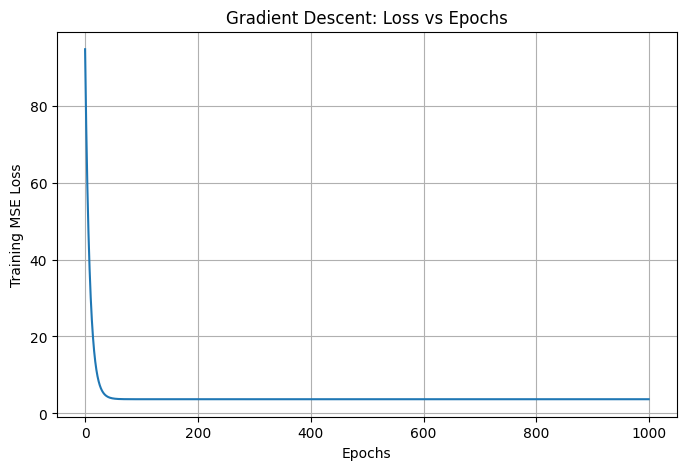

In [16]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel("Epochs")

plt.ylabel("Training MSE Loss")

plt.title("Gradient Descent: Loss vs Epochs")

plt.grid(True)

plt.show()

In [17]:
def run_gradient_descent(lr, epochs=500):

    w = 0.0
    b = 0.0

    losses = []

    for i in range(epochs):

        pred = w * Xtr[:, 0] + b

        error = pred - ytr

        loss = np.mean(error ** 2)

        losses.append(loss)

        dw = (2 / len(Xtr)) * np.sum(
            Xtr[:, 0] * error
        )

        db = (2 / len(Xtr)) * np.sum(error)

        w = w - lr * dw

        b = b - lr * db

    return losses

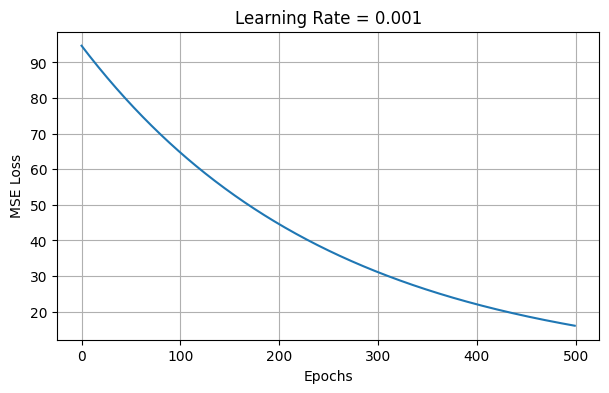

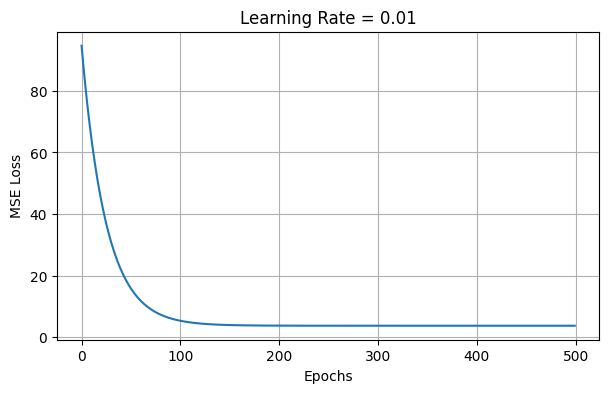

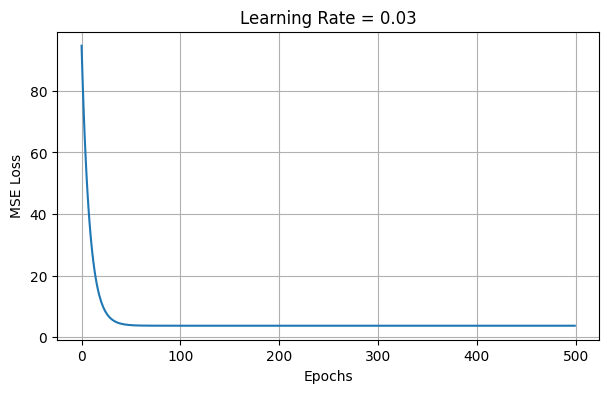

In [18]:
learning_rates = [0.001, 0.01, 0.03]

for lr in learning_rates:

    losses = run_gradient_descent(lr)

    plt.figure(figsize=(7,4))

    plt.plot(losses)

    plt.xlabel("Epochs")

    plt.ylabel("MSE Loss")

    plt.title(
        f"Learning Rate = {lr}"
    )

    plt.grid(True)

    plt.show()